# simTOP: analysis of the experiment
Reads `../results/runs.csv` and `../results/best.csv` (1 269 runs: 141 instances of p1-p3 x c x alpha), writes summary tables to `../results/` and figures to `../results/figures/`.
Gap = 100 (BKS - exp_reward) / BKS, with BKS the deterministic best-known solution of Chao et al. and exp_reward the intensive-simulation mean. `fail_rate` is a percentage of routes.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RES = Path("../results")
FIG = RES / "figures"
FIG.mkdir(exist_ok=True)
runs = pd.read_csv(RES / "runs.csv")
best = pd.read_csv(RES / "best.csv")
LEVEL = {0.05: "L", 0.25: "M", 0.75: "H"}
runs["level"] = runs.c.map(LEVEL)
best["level"] = best.c.map(LEVEL)
print(len(runs), "runs,", len(best), "best rows,", runs.instance.nunique(), "instances")

1269 runs, 423 best rows, 141 instances


## 1. Alpha x c matrix (all 9 runs per instance)

In [2]:
mean_t = runs.pivot_table(index="alpha", columns="c", values="gap_pct", aggfunc="mean")
med_t = runs.pivot_table(index="alpha", columns="c", values="gap_pct", aggfunc="median")
matrix = pd.concat({"mean_gap_pct": mean_t, "median_gap_pct": med_t}, axis=1).round(2)
matrix.to_csv(RES / "gap_alpha_c_matrix.csv")
matrix

mean_gap_pct               median_gap_pct              
c             0.05   0.25   0.75           0.05   0.25   0.75
alpha                                                        
0.25         16.69  26.92  31.78          16.90  27.52  33.02
0.50         16.86  26.83  31.97          16.94  28.56  32.42
0.75         16.29  26.90  31.94          17.07  28.77  33.45

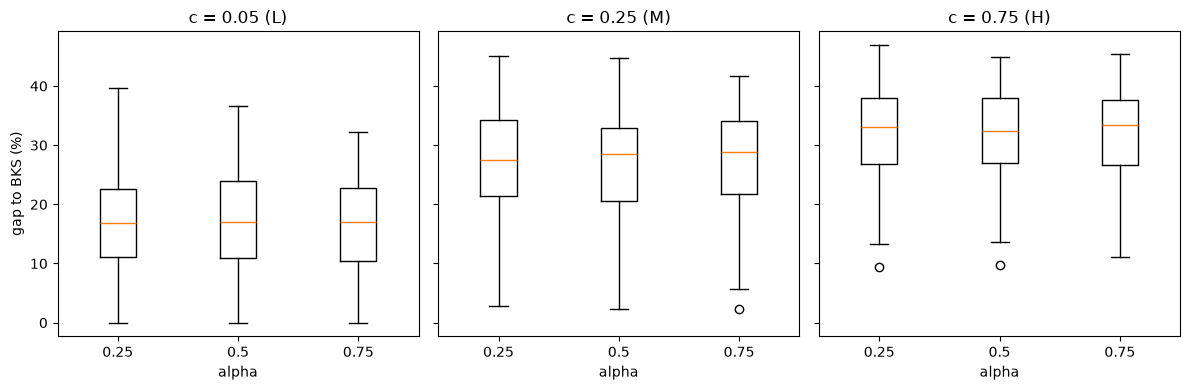

In [3]:
alphas = sorted(runs.alpha.unique())
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for ax, c in zip(axes, sorted(runs.c.unique())):
    ax.boxplot([runs[(runs.c == c) & (runs.alpha == a)].gap_pct for a in alphas],
               tick_labels=[str(a) for a in alphas])
    ax.set_title(f"c = {c} ({LEVEL[c]})")
    ax.set_xlabel("alpha")
axes[0].set_ylabel("gap to BKS (%)")
fig.tight_layout()
fig.savefig(FIG / "gap_by_c_alpha.png", dpi=150)
plt.show()

## 2. Best alpha per (instance, c) against the paper's Fig. 3
The SimHeu reference values are approximate, **read by eye** from Fig. 3 of Juan et al. (2019) (about +-1-2 points): median, Q1-Q3, whiskers and the one outlier of SimHeu-L (about 26).

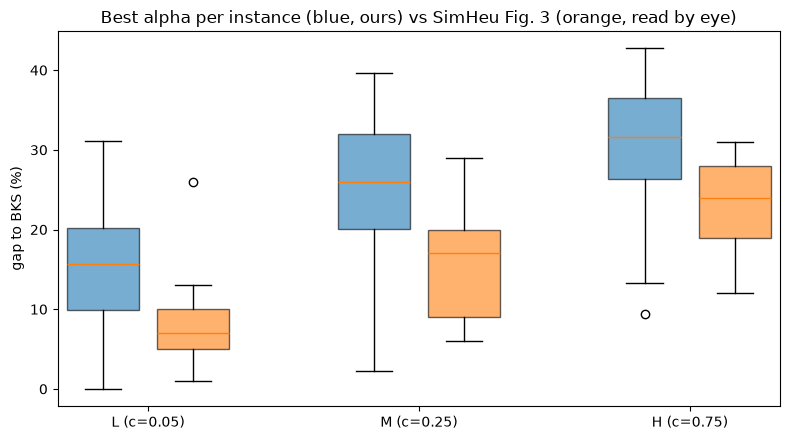

,q1,median,q3,mean,paper_q1,paper_median,paper_q3
level,,,,,,,
L,9.90,15.69,20.23,14.65,5,7,10
M,20.04,26.02,31.97,25.02,9,17,20
H,26.35,31.56,36.44,30.51,19,24,28


In [4]:
paper = {"L": dict(med=7, q1=5, q3=10, whislo=1, whishi=13), "M": dict(med=17, q1=9, q3=20, whislo=6, whishi=29),
         "H": dict(med=24, q1=19, q3=28, whislo=12, whishi=31)}
levels = ["L", "M", "H"]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot([best[best.level == l].gap_pct for l in levels], positions=[1, 4, 7], widths=0.8, patch_artist=True,
           boxprops=dict(facecolor="tab:blue", alpha=0.6))
stats = [dict(paper[l], fliers=[26] if l == "L" else [], label=l) for l in levels]
ax.bxp(stats, positions=[2, 5, 8], widths=0.8, patch_artist=True, boxprops=dict(facecolor="tab:orange", alpha=0.6))
ax.set_xticks([1.5, 4.5, 7.5])
ax.set_xticklabels(["L (c=0.05)", "M (c=0.25)", "H (c=0.75)"])
ax.set_ylabel("gap to BKS (%)")
ax.set_title("Best alpha per instance (blue, ours) vs SimHeu Fig. 3 (orange, read by eye)")
fig.tight_layout()
fig.savefig(FIG / "gap_best_vs_paper.png", dpi=150)
plt.show()
q = best.groupby("level").gap_pct.quantile([0.25, 0.5, 0.75]).unstack().loc[levels]
q.columns = ["q1", "median", "q3"]
q["mean"] = best.groupby("level").gap_pct.mean().loc[levels]
q["paper_q1"] = [paper[l]["q1"] for l in levels]
q["paper_median"] = [paper[l]["med"] for l in levels]
q["paper_q3"] = [paper[l]["q3"] for l in levels]
q = q.round(2)
q.to_csv(RES / "gap_best_by_level.csv")
q

### Monotonicity of the mean gap

In [5]:
mg = best.groupby("level").gap_pct.mean().loc[levels]
print("best alpha, mean gap:", mg.round(2).to_dict())
print("gap(L) < gap(M) < gap(H):", bool(mg["L"] < mg["M"] < mg["H"]))
mg_all = runs.groupby("level").gap_pct.mean().loc[levels]
print("all runs, mean gap:", mg_all.round(2).to_dict(), "monotone:", bool(mg_all["L"] < mg_all["M"] < mg_all["H"]))

best alpha, mean gap: {'L': 14.65, 'M': 25.02, 'H': 30.51}
gap(L) < gap(M) < gap(H): True
all runs, mean gap: {'L': 16.62, 'M': 26.88, 'H': 31.9} monotone: True


## 3. Gap by set and against tmax
With Var = c t the relative uncertainty of a route is sqrt(c / E_r), larger for short routes, so one might expect larger gaps when tmax is small. The data show the opposite: the gap tends to grow with tmax (Spearman correlation printed below) and p2, the set with the smallest tmax, has the lowest gap. Set and tmax are confounded, and part of the trend is already in the deterministic gap. A likely reason is that the routes are built close to tmax (see the slack table below), and a route whose expected time equals tmax fails a little under half of the time whatever c is.

        mean               median              
level      L      M      H      L      M      H
set                                            
p1     18.38  29.37  33.87  18.72  30.75  35.31
p2     10.36  19.33  25.19   7.79  17.65  26.29
p3     14.02  24.68  30.75  13.46  25.12  31.72
median tmax by set: {'p1': 17.5, 'p2': 10.0, 'p3': 20.6}
Spearman(tmax, gap) by level: {'L': 0.49, 'M': 0.56, 'H': 0.67}


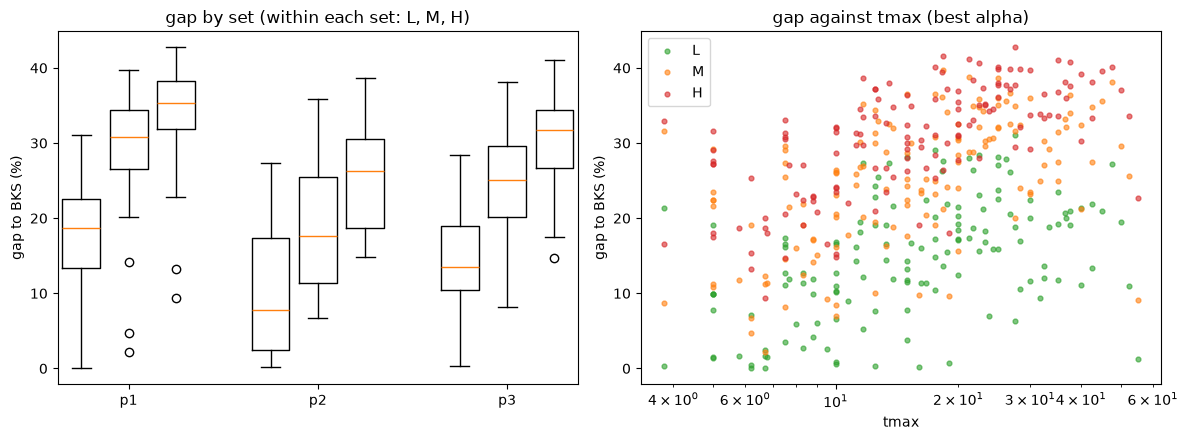

In [6]:
by_set = best.pivot_table(index="set", columns="level", values="gap_pct", aggfunc=["mean", "median"])
by_set = by_set[[("mean", l) for l in levels] + [("median", l) for l in levels]].round(2)
by_set.to_csv(RES / "gap_by_set_level.csv")
print(by_set)
print("median tmax by set:", best.groupby("set").tmax.median().to_dict())
print("Spearman(tmax, gap) by level:", {l: round(float(best[best.level == l][["tmax", "gap_pct"]].corr(method="spearman").iloc[0, 1]), 2) for l in levels})
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sets = sorted(best.set.unique())
for k, l in enumerate(levels):
    axes[0].boxplot([best[(best.level == l) & (best.set == s)].gap_pct for s in sets],
                    positions=np.arange(len(sets)) * 4 + k, widths=0.8)
axes[0].set_xticks(np.arange(len(sets)) * 4 + 1)
axes[0].set_xticklabels(sets)
axes[0].set_title("gap by set (within each set: L, M, H)")
axes[0].set_ylabel("gap to BKS (%)")
for l, col in zip(levels, ["tab:green", "tab:orange", "tab:red"]):
    d = best[best.level == l]
    axes[1].scatter(d.tmax, d.gap_pct, s=12, alpha=0.6, c=col, label=l)
axes[1].set_xscale("log")
axes[1].set_xlabel("tmax")
axes[1].set_ylabel("gap to BKS (%)")
axes[1].legend()
axes[1].set_title("gap against tmax (best alpha)")
fig.tight_layout()
fig.savefig(FIG / "gap_by_set_tmax.png", dpi=150)
plt.show()

In [7]:
import simtop as st
for col in ("det_gap_pct", "uncert_loss_pct"):
    print(f"Spearman(tmax, {col}) by level:", {l: round(float(best[best.level == l][["tmax", col]].corr(method="spearman").iloc[0, 1]), 2) for l in levels})
# slack of the winners' routes: expected time / tmax
ratios = []
for _, row in best.iterrows():
    inst = st.load_instance(row.instance)
    for route in str(row.routes).split(";"):
        if route:
            ratios.append((row.level, st.route_time(inst, [int(v) for v in route.split("-")]) / row.tmax))
slack = pd.DataFrame(ratios, columns=["level", "ratio"])
slack_tab = slack.groupby("level").ratio.agg(median="median", q1=lambda x: x.quantile(0.25), p90=lambda x: x.quantile(0.9),
                                            share_within_1pct=lambda x: (x > 0.99).mean()).loc[levels].round(3)
slack_tab.to_csv(RES / "route_slack_by_level.csv")
slack_tab

Spearman(tmax, det_gap_pct) by level: {'L': 0.56, 'M': 0.54, 'H': 0.59}
Spearman(tmax, uncert_loss_pct) by level: {'L': 0.33, 'M': 0.44, 'H': 0.52}


,median,q1,p90,share_within_1pct
level,,,,
L,0.928,0.860,0.979,0.038
M,0.927,0.851,0.983,0.061
H,0.932,0.853,0.988,0.084


## 4. Gap decomposition: deterministic gap vs loss due to uncertainty
`det_gap_pct` is the gap of the winner's deterministic reward; `uncert_loss_pct` = 100 (1 - exp_reward / det_reward). In the bar chart the second bar is (1 - det_gap/100) * uncert_loss, so both bars add up to `gap_pct` exactly.

      gap_pct        det_gap_pct        uncert_loss_pct       
         mean median        mean median            mean median
level                                                         
L       14.65  15.69        3.15    0.0           11.86  11.43
M       25.02  26.02        2.96    0.0           22.72  23.36
H       30.51  31.56        2.41    0.0           28.79  29.80


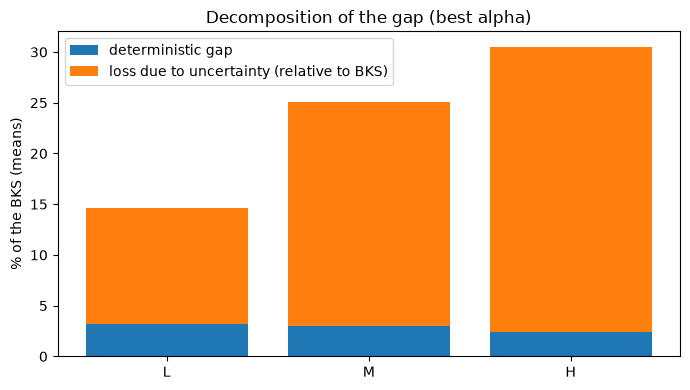

In [8]:
dec = best.groupby("level")[["gap_pct", "det_gap_pct", "uncert_loss_pct"]].agg(["mean", "median"]).loc[levels].round(2)
dec.to_csv(RES / "gap_decomposition_by_level.csv")
print(dec)
det_m = [best[best.level == l].det_gap_pct.mean() for l in levels]
# loss relative to the BKS, so that det_gap + this = gap_pct exactly
unc_m = [((1 - best.det_gap_pct / 100) * best.uncert_loss_pct)[best.level == l].mean() for l in levels]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(levels, det_m, label="deterministic gap")
ax.bar(levels, unc_m, bottom=det_m, label="loss due to uncertainty (relative to BKS)")
ax.set_ylabel("% of the BKS (means)")
ax.legend()
ax.set_title("Decomposition of the gap (best alpha)")
fig.tight_layout()
fig.savefig(FIG / "gap_decomposition.png", dpi=150)
plt.show()

## 5. Failed routes (% of routes overrunning tmax in the intensive simulation)

        mean  median    max
level                      
L      12.73   12.73  29.60
M      23.57   25.10  39.35
H      29.45   30.72  42.70


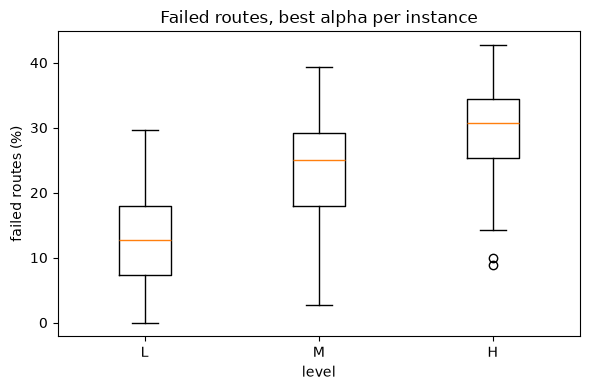

In [9]:
fr = best.groupby("level").fail_rate.agg(["mean", "median", "max"]).loc[levels].round(2)
fr.to_csv(RES / "fail_rate_by_level.csv")
print(fr)
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot([best[best.level == l].fail_rate for l in levels], tick_labels=levels)
ax.set_ylabel("failed routes (%)")
ax.set_xlabel("level")
ax.set_title("Failed routes, best alpha per instance")
fig.tight_layout()
fig.savefig(FIG / "fail_rate_by_level.png", dpi=150)
plt.show()

## 6. Computing time per run (seconds; runs executed in a process pool)

In [10]:
tm = runs.pivot_table(index="set", columns="level", values="time_s", aggfunc=["mean", "max"])
tm = tm[[("mean", l) for l in levels] + [("max", l) for l in levels]].round(3)
tm.to_csv(RES / "time_by_set_level.csv")
print(tm)
print("sum of run times (s):", round(runs.time_s.sum(), 1))

        mean                  max              
level      L      M      H      L      M      H
set                                            
p1     0.159  0.165  0.163  0.230  0.234  0.226
p2     0.072  0.074  0.071  0.119  0.147  0.105
p3     0.164  0.165  0.165  0.234  0.226  0.230
sum of run times (s): 180.6


## 7. Other facts

In [11]:
print("winner is the greedy candidate (best-alpha rows):", round(100 * best.winner_is_greedy.mean(), 1), "%")
print("gap > 50 %: runs", int((runs.gap_pct > 50).sum()), "; best-alpha rows", int((best.gap_pct > 50).sum()))
print("alpha chosen as best:", best.alpha.value_counts().sort_index().to_dict())
cols = ["instance", "c", "alpha", "tmax", "bks", "det_reward", "exp_reward", "gap_pct"]
print(best.sort_values("gap_pct", ascending=False)[cols].head(8).round({"exp_reward": 1, "gap_pct": 1}).to_string(index=False))

winner is the greedy candidate (best-alpha rows): 13.2 %
gap > 50 %: runs 0 ; best-alpha rows 0
alpha chosen as best: {0.25: 142, 0.5: 138, 0.75: 143}
instance    c  alpha  tmax  bks  det_reward  exp_reward  gap_pct
  p1.2.k 0.75   0.50  27.5  175       175.0       100.2     42.7
  p1.3.k 0.75   0.50  18.3  135       135.0        78.9     41.6
  p1.4.r 0.75   0.75  21.2  210       195.0       123.5     41.2
  p3.3.s 0.75   0.75  35.0  720       660.0       424.5     41.0
  p3.2.m 0.75   0.75  37.5  620       570.0       367.5     40.7
  p3.2.g 0.75   0.25  22.5  360       340.0       213.7     40.6
  p3.2.q 0.75   0.50  47.5  760       710.0       454.6     40.2
  p1.4.n 0.75   0.25  17.5  155       140.0        92.7     40.2
